<a href="https://colab.research.google.com/github/RohanSNikam/Logistics-Delivery-Time-Analysis/blob/main/notebooks/Week-2_logistics_delivery_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/Week2_Logistics_Raw_Dataset_1000_Rows.csv")

In [ ]:
df.head()

,order_id,order_date,origin_city,destination_city,distance_km,traffic_level,weather,vehicle_type,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,delivery_status,inventory_qty
0,LOG100555,2026-01-15,Nashik,Nagpur,105.5,High,Clear,bike,13550.21,180,203.0,535.34,Delayed,19.0
1,LOG100331,2026-01-13,Satara,Aurangabad,440.2,Medium,Clear,Truck,5898.03,541,602.0,1337.10,Delayed,103.0
2,LOG100974,2026-07-20,Satara,Aurangabad,19.1,Medium,Foggy,Van,20909.87,388,459.0,241.92,Delayed,99.0
3,LOG100157,2026-06-26,Ahmednagar,Mumbai,407.9,High,Clear,Bike,19699.13,486,552.0,1705.47,Delayed,78.0
4,LOG100322,2026-10-04,Satara,Thane,234.2,Medium,Clear,Truck,4527.08,342,455.0,826.18,Delayed,76.0


In [ ]:
df.shape

(1000, 14)

In [ ]:
df.tail()

,order_id,order_date,origin_city,destination_city,distance_km,traffic_level,weather,vehicle_type,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,delivery_status,inventory_qty
995,LOG100985,2026-06-02,Satara,Aurangabad,294.9,Low,Rainy,Tempo,10926.24,515,663.0,1432.85,Delayed,11.0
996,LOG100844,2026-02-27,Nashik,Satara,218.4,High,Rainy,Van,16573.54,458,974.0,891.13,Delayed,121.0
997,LOG100862,2026-02-15,Ahmednagar,Thane,299.9,High,Cloudy,Tempo,15266.44,100,161.0,1276.27,Delayed,8.0
998,LOG100692,2026-06-24,Aurangabad,Ahmednagar,223.8,High,Rainy,Bike,19421.10,154,333.0,912.55,Delayed,108.0
999,LOG100778,2026-01-23,Solapur,Mumbai,269.6,High,Clear,Bike,11852.39,810,1079.0,1337.86,Delayed,90.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   order_id                   1000 non-null   object 
 1   order_date                 1000 non-null   object 
 2   origin_city                1000 non-null   object 
 3   destination_city           1000 non-null   object 
 4   distance_km                977 non-null    float64
 5   traffic_level              988 non-null    object 
 6   weather                    982 non-null    object 
 7   vehicle_type               1000 non-null   object 
 8   order_value_inr            1000 non-null   float64
 9   promised_delivery_minutes  1000 non-null   int64  
 10  actual_delivery_minutes    985 non-null    float64
 11  delivery_cost_inr          984 non-null    float64
 12  delivery_status            1000 non-null   object 
 13  inventory_qty              980 non-null    float6

In [ ]:
df.columns

Index(['order_id', 'order_date', 'origin_city', 'destination_city',
       'distance_km', 'traffic_level', 'weather', 'vehicle_type',
       'order_value_inr', 'promised_delivery_minutes',
       'actual_delivery_minutes', 'delivery_cost_inr', 'delivery_status',
       'inventory_qty'],
      dtype='object')

In [ ]:
df.dtypes

,0
order_id,object
order_date,object
origin_city,object
destination_city,object
distance_km,float64
traffic_level,object
weather,object
vehicle_type,object
order_value_inr,float64
promised_delivery_minutes,int64


In [ ]:
df.describe()

,distance_km,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,inventory_qty
count,977.000000,1000.000000,1000.000000,985.000000,984.000000,980.000000
mean,267.511259,12042.401570,492.752000,631.364467,1176.615681,75.743878
std,168.173828,7216.071514,243.611447,405.624847,2105.633135,50.642176
min,-5.000000,276.890000,60.000000,5.000000,5.000000,-10.000000
25%,136.700000,5707.425000,284.000000,333.000000,624.967500,38.000000
50%,276.800000,11540.845000,499.500000,586.000000,1085.590000,75.000000
75%,388.500000,18202.407500,711.250000,870.000000,1461.222500,113.250000
max,2500.000000,24988.840000,896.000000,5000.000000,50000.000000,900.000000


In [ ]:
df.isnull().sum()

,0
order_id,0
order_date,0
origin_city,0
destination_city,0
distance_km,23
traffic_level,12
weather,18
vehicle_type,0
order_value_inr,0
promised_delivery_minutes,0


In [ ]:
df_clean = df.copy()

In [ ]:
numerical_cols = [
    'distance_km',
    'actual_delivery_minutes',
    'delivery_cost_inr',
    'inventory_qty'
]

for col in numerical_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

In [ ]:
categorical_missing_cols = [
    'traffic_level',
    'weather'
]

for col in categorical_missing_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].mode()[0]
    )

In [ ]:
df_clean.isnull().sum()

,0
order_id,0
order_date,0
origin_city,0
destination_city,0
distance_km,0
traffic_level,0
weather,0
vehicle_type,0
order_value_inr,0
promised_delivery_minutes,0


In [ ]:
df_clean.duplicated().sum()

np.int64(15)

In [ ]:
df_clean = df_clean.drop_duplicates()

In [ ]:
df_clean.shape

(985, 14)

In [ ]:
categorical_cols = [
    'traffic_level',
    'weather',
    'vehicle_type',
    'delivery_status'
]

for col in categorical_cols:
    df_clean[col] = df_clean[col].str.strip().str.title()

In [ ]:
for col in categorical_cols:
    print("\n", col)
    print(df_clean[col].unique())


 traffic_level
['High' 'Medium' 'Low']

 weather
['Clear' 'Foggy' 'Rainy' 'Cloudy']

 vehicle_type
['Bike' 'Truck' 'Van' 'Tempo']

 delivery_status
['Delayed' 'On-Time']


In [ ]:
df_clean.dtypes

,0
order_id,object
order_date,object
origin_city,object
destination_city,object
distance_km,float64
traffic_level,object
weather,object
vehicle_type,object
order_value_inr,float64
promised_delivery_minutes,int64


In [ ]:
df_clean['order_date'] = pd.to_datetime(
    df_clean['order_date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

In [ ]:

df_clean['order_date'].dtype

dtype('<M8[ns]')

In [ ]:

df_clean['order_date'].head()

,order_date
0,2026-01-15
1,2026-01-13
2,2026-07-20
3,2026-06-26
4,2026-10-04


In [ ]:


df_clean.dtypes

,0
order_id,object
order_date,datetime64[ns]
origin_city,object
destination_city,object
distance_km,float64
traffic_level,object
weather,object
vehicle_type,object
order_value_inr,float64
promised_delivery_minutes,int64


In [ ]:

df_clean['year'] = df_clean['order_date'].dt.year

df_clean['month'] = df_clean['order_date'].dt.month

df_clean['day'] = df_clean['order_date'].dt.day

In [ ]:


df_clean[['order_date', 'year', 'month', 'day']].head()

,order_date,year,month,day
0,2026-01-15,2026,1,15
1,2026-01-13,2026,1,13
2,2026-07-20,2026,7,20
3,2026-06-26,2026,6,26
4,2026-10-04,2026,10,4


In [ ]:

df_clean.dtypes

,0
order_id,object
order_date,datetime64[ns]
origin_city,object
destination_city,object
distance_km,float64
traffic_level,object
weather,object
vehicle_type,object
order_value_inr,float64
promised_delivery_minutes,int64


In [ ]:

# Check minimum values of numerical columns

df_clean[numerical_cols].min()

,0
distance_km,-5.0
actual_delivery_minutes,5.0
delivery_cost_inr,5.0
inventory_qty,-10.0


In [ ]:

df_clean[numerical_cols].max()

,0
distance_km,2500.0
actual_delivery_minutes,5000.0
delivery_cost_inr,50000.0
inventory_qty,900.0


In [ ]:
print("Invalid distance:",
      (df_clean['distance_km'] <= 0).sum())

print("Invalid delivery time:",
      (df_clean['actual_delivery_minutes'] <= 0).sum())

print("Invalid delivery cost:",
      (df_clean['delivery_cost_inr'] <= 0).sum())

print("Invalid inventory:",
      (df_clean['inventory_qty'] < 0).sum())

Invalid distance: 2
Invalid delivery time: 0
Invalid delivery cost: 0
Invalid inventory: 1


In [ ]:

# Replace invalid values with NaN

df_clean.loc[df_clean['distance_km'] <= 0, 'distance_km'] = np.nan

df_clean.loc[df_clean['actual_delivery_minutes'] <= 0, 'actual_delivery_minutes'] = np.nan

df_clean.loc[df_clean['delivery_cost_inr'] <= 0, 'delivery_cost_inr'] = np.nan

df_clean.loc[df_clean['inventory_qty'] < 0, 'inventory_qty'] = np.nan

In [ ]:

for col in numerical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())


In [ ]:

outlier_cols = [
    'distance_km',
    'actual_delivery_minutes',
    'delivery_cost_inr',
    'inventory_qty'
]

for col in outlier_cols:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Outlier count:", len(outliers))


Column: distance_km
Q1: 141.4
Q3: 385.9
IQR: 244.49999999999997
Lower limit: -225.34999999999994
Upper limit: 752.6499999999999
Outlier count: 2

Column: actual_delivery_minutes
Q1: 342.0
Q3: 865.0
IQR: 523.0
Lower limit: -442.5
Upper limit: 1649.5
Outlier count: 7

Column: delivery_cost_inr
Q1: 626.33
Q3: 1450.3
IQR: 823.9699999999999
Lower limit: -609.6249999999999
Upper limit: 2686.255
Outlier count: 2

Column: inventory_qty
Q1: 39.0
Q3: 112.0
IQR: 73.0
Lower limit: -70.5
Upper limit: 221.5
Outlier count: 1


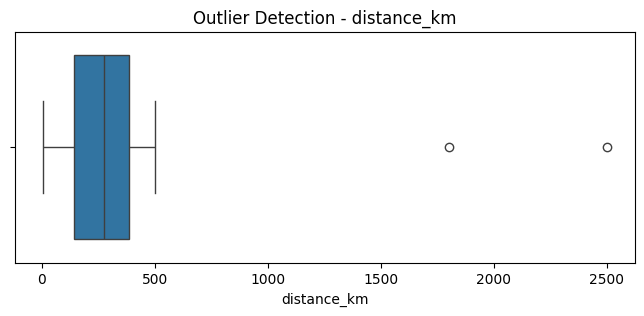

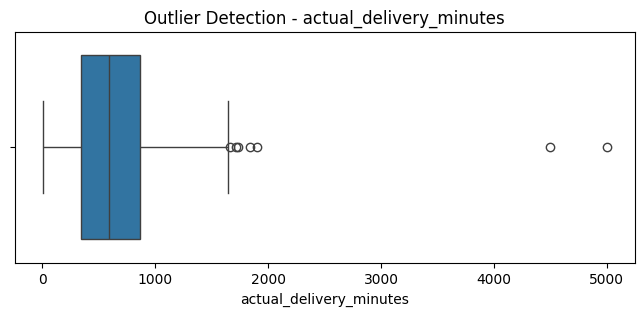

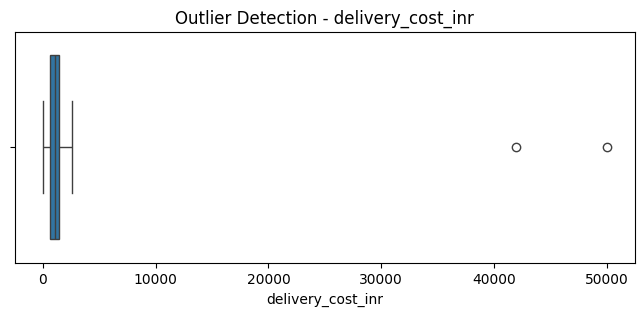

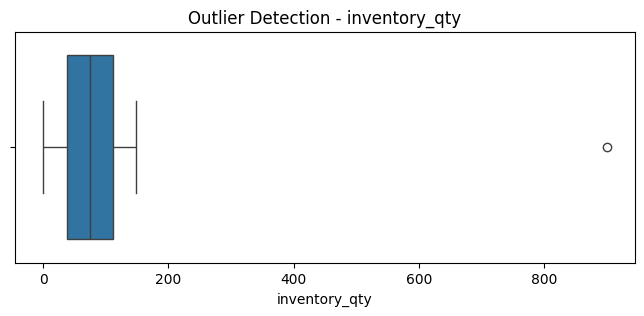

In [ ]:

for col in outlier_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df_clean[col])

    plt.title("Outlier Detection - " + col)

    plt.show()

In [ ]:

for col in outlier_cols:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(
        lower=lower,
        upper=upper
    )

In [ ]:

df_clean[outlier_cols].describe()

,distance_km,actual_delivery_minutes,delivery_cost_inr,inventory_qty
count,985.000000,985.000000,985.000000,985.000000
mean,265.088731,625.486802,1086.689716,74.797462
std,143.610489,358.249882,552.610651,42.795100
min,5.000000,5.000000,5.000000,0.000000
25%,141.400000,342.000000,626.330000,39.000000
50%,276.800000,586.000000,1085.590000,75.000000
75%,385.900000,865.000000,1450.300000,112.000000
max,752.650000,1649.500000,2686.255000,221.500000


In [ ]:

from sklearn.preprocessing import MinMaxScaler

In [ ]:

scale_cols = [
    'distance_km',
    'order_value_inr',
    'promised_delivery_minutes',
    'actual_delivery_minutes',
    'delivery_cost_inr',
    'inventory_qty'
]


In [ ]:

df_minmax = df_clean.copy()

In [ ]:
scaler = MinMaxScaler()

df_minmax[scale_cols] = scaler.fit_transform(
    df_minmax[scale_cols]
)

In [ ]:


df_minmax[scale_cols].head()

,distance_km,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,inventory_qty
0,0.134421,0.537122,0.143541,0.120401,0.197795,0.085779
1,0.582091,0.227466,0.575359,0.363028,0.496820,0.465011
2,0.018859,0.834939,0.392344,0.276072,0.088362,0.446953
3,0.538889,0.785945,0.509569,0.332624,0.634207,0.352144
4,0.306561,0.171989,0.337321,0.273639,0.306267,0.343115


In [ ]:

df_minmax[scale_cols].agg(['min', 'max'])

,distance_km,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,inventory_qty
min,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0


In [ ]:


from sklearn.preprocessing import StandardScaler

In [ ]:
df_standard = df_clean.copy()

In [ ]:
standard_scaler = StandardScaler()

df_standard[scale_cols] = standard_scaler.fit_transform(
    df_standard[scale_cols]
)


In [ ]:


df_standard[scale_cols].head()

,distance_km,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,inventory_qty
0,-1.111825,0.210279,-1.292317,-1.179907,-0.998225,-1.304491
1,1.219968,-0.852674,0.195004,-0.065593,0.453371,0.659348
2,-1.713758,1.232599,-0.435356,-0.464959,-1.529465,0.565832
3,0.994940,1.064417,-0.031596,-0.205231,1.120309,0.074872
4,-0.215196,-1.043111,-0.624876,-0.476130,-0.471656,0.028114


In [ ]:

df_standard[scale_cols].agg(['mean', 'std'])

,distance_km,order_value_inr,promised_delivery_minutes,actual_delivery_minutes,delivery_cost_inr,inventory_qty
mean,7.213632e-18,1.875544e-16,-6.852950e-17,5.770905e-17,-2.164090e-17,-4.869201e-17
std,1.000508e+00,1.000508e+00,1.000508e+00,1.000508e+00,1.000508e+00,1.000508e+00


In [ ]:

comparison = pd.DataFrame({
    'Original_Distance': df_clean['distance_km'].head(10),
    'MinMax_Distance': df_minmax['distance_km'].head(10),
    'Standardized_Distance': df_standard['distance_km'].head(10)
})

comparison

,Original_Distance,MinMax_Distance,Standardized_Distance
0,105.5,0.134421,-1.111825
1,440.2,0.582091,1.219968
2,19.1,0.018859,-1.713758
3,407.9,0.538889,0.994940
4,234.2,0.306561,-0.215196
5,168.1,0.218150,-0.675703
6,102.2,0.130007,-1.134816
7,420.8,0.556143,1.084812
8,283.2,0.372099,0.126178
9,397.8,0.525380,0.924575


In [ ]:

print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

Original Dataset: (1000, 14)
Cleaned Dataset: (985, 17)


In [ ]:


df_clean.isnull().sum()


,0
order_id,0
order_date,0
origin_city,0
destination_city,0
distance_km,0
traffic_level,0
weather,0
vehicle_type,0
order_value_inr,0
promised_delivery_minutes,0


In [ ]:

comparison_summary = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Total Columns',
        'Missing Values',
        'Duplicate Rows'
    ],
    'Before Cleaning': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ],
    'After Cleaning': [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum()
    ]
})

comparison_summary


,Metric,Before Cleaning,After Cleaning
0,Total Rows,1000,985
1,Total Columns,14,17
2,Missing Values,104,0
3,Duplicate Rows,15,0


In [ ]:

with pd.ExcelWriter('Week2_Logistics_Preprocessed.xlsx') as writer:

    df_clean.to_excel(
        writer,
        sheet_name='Cleaned_Data',
        index=False
    )

    df_minmax.to_excel(
        writer,
        sheet_name='MinMax_Scaled',
        index=False
    )

    df_standard.to_excel(
        writer,
        sheet_name='Standardized',
        index=False
    )


In [ ]:

from google.colab import files

files.download('Week2_Logistics_Preprocessed.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>